# 5. TAD calling

`uchrom.strc.tad.call_tads_by_pval` is a GPU-accelerated reimplementation
of the ArcFISH TAD caller (Yu et al. 2025).  For each candidate boundary
position it asks: is the variance *inside* the window smaller than the
variance *across* the window?  A per-axis F-test answers this and ACAT
combines the three axes into one p-value per bin.  Local minima in that
p-value are scored as TAD boundaries; the hierarchical option emits
nested TAD levels by repeatedly dropping the weakest boundary.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from uchrom import ChromData
from uchrom.strc.tad import call_tads_by_pval, TADCallerParams
from uchrom.fea import mean_distance_matrix
from uchrom.pl import plot_distance_matrix


## Load the example FOF-CT

Use the same synthetic file produced by tutorial 2 / 4; in practice you would point this at a real dataset such as Takei et al. 2021 (4DN `4DNFIHF3JCBY`).


In [2]:
from pathlib import Path
import os

# Prefer real Takei 2021 data if downloaded; otherwise fall back to
# the synthetic FOF-CT produced by tutorial 4.
candidates = [
    Path.home() / 'Downloads' / 'ArcFISH_data' / '4DNFIHF3JCBY.csv',
    Path.home() / 'Downloads' / 'ArcFISH_data' / '4DNFIHF3JCBY.h5cd',
    Path.home() / 'Downloads' / '4DNFIHF3JCBY.csv',
]
for p in [Path.cwd(), *Path.cwd().parents]:
    candidates.append(p / 'example-data' / 'fofct_core.csv')
FOFCT = next((str(c) for c in candidates if c.exists()), None)
if FOFCT is None:
    raise FileNotFoundError('Run tutorial 4 first or download Takei 2021 (4DNFIHF3JCBY).')
print(FOFCT)
cd = ChromData.read(FOFCT) if FOFCT.endswith(".h5cd") else ChromData.from_fofct(FOFCT)
cd


/Users/weizexu/Downloads/ArcFISH_data/4DNFIHF3JCBY.csv


ChromData: n_spots=316995, n_traces=8285, n_cells=201
  spots:   ['chrom', 'start', 'end', 'trace_id', 'spot_id', 'cell_id', 'extra_cell_roi_id']
  uns:     ['fofct_header', 'xyz_unit', 'genome_assembly']

## Run the TAD caller


In [3]:
chrom = cd.spots['chrom'].astype(str).iloc[0]
params = TADCallerParams(
    window_bp=1e5,     # boundary window (bp)
    fdr_cutoff=0.1,
    hierarchical=True,
    max_levels=3,
)
tads = call_tads_by_pval(cd, chrom=chrom, params=params, device='auto', verbose=True)
print(f'{len(tads)} TAD entries across {tads["level"].nunique()} levels')
tads.head(15)


[tad/chr1] variance cube...
[tad/chr1] filter + normalise...


[tad/chr1] axis weights: [0.323 0.324 0.353]
12 TAD entries across 3 levels


,chrom,start,end,level,score,pval,fdr
0,chr1,135600000,136325000,1,1.866439,0.013601,0.072537
1,chr1,136325000,136475000,1,4.295254,0.000051,0.000811
2,chr1,136475000,136550000,1,4.295254,0.000051,0.000811
3,chr1,136550000,136750000,1,2.299543,0.005017,0.040137
4,chr1,136750000,137100000,1,2.299543,0.005017,0.040137
5,chr1,135600000,136325000,2,1.866439,0.013601,0.072537
6,chr1,136325000,136475000,2,4.295254,0.000051,0.000811
7,chr1,136475000,136750000,2,4.295254,0.000051,0.000811
8,chr1,136750000,137100000,2,2.299543,0.005017,0.040137
9,chr1,135600000,136475000,3,4.295254,0.000051,0.000811


## Overlay TAD blocks on the median distance matrix

A good TAD call should outline the **low-distance blocks** along the diagonal of the population-median pairwise distance matrix — the classic Hi-C TAD-view.  We draw each TAD as a rectangle along the diagonal.


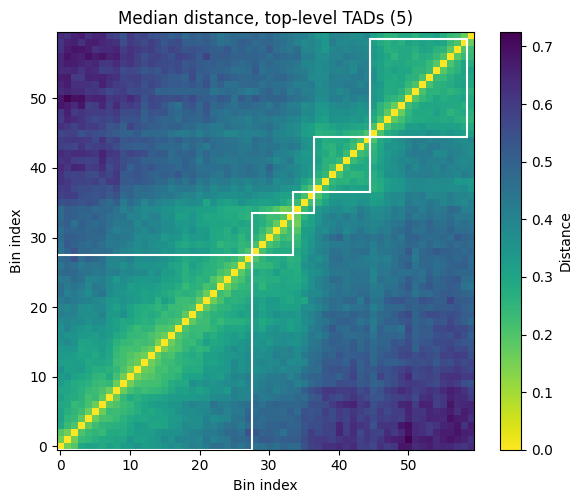

In [4]:
from matplotlib.patches import Rectangle

df = cd.get_chrom(chrom).to_dataframe()
dmat, bin_ids, n_traces = mean_distance_matrix(df, chrom=chrom)
B = len(bin_ids)
mid_bp = np.array([(s + e) * 0.5 for (s, e) in bin_ids])

def bin_of(bp):
    return int(np.argmin(np.abs(mid_bp - bp)))

def draw_tad_rects(ax, tad_df, **kw):
    for _, r in tad_df.iterrows():
        a = bin_of(r['start'])
        b = bin_of(r['end']) - 1  # inclusive end bin
        if b - a < 1:
            continue
        ax.add_patch(Rectangle(
            (a - 0.5, a - 0.5), b - a + 1, b - a + 1,
            fill=False, **kw,
        ))

# Top-level TADs only
top_level = tads[tads['level'] == tads['level'].min()]
fig = plot_distance_matrix(dmat, title=f'Median distance, top-level TADs ({len(top_level)})')
draw_tad_rects(fig.axes[0], top_level, edgecolor='white', linewidth=1.5)
plt.show()


## Hierarchy — nested TADs

With `hierarchical=True`, level 1 keeps only the strongest boundaries (coarse TADs); deeper levels add weaker ones.  Overlaying a different colour per level on the same heatmap makes the nesting obvious.


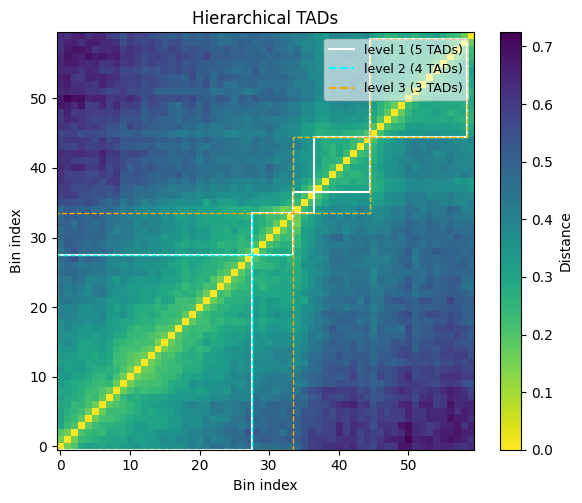

In [5]:
fig = plot_distance_matrix(dmat, title='Hierarchical TADs')
ax = fig.axes[0]
level_colors = {1: 'white', 2: 'cyan', 3: 'orange', 4: 'magenta'}
for lv in sorted(tads['level'].unique()):
    draw_tad_rects(
        ax, tads[tads['level'] == lv],
        edgecolor=level_colors.get(lv, 'yellow'),
        linewidth=1.5 if lv == 1 else 1.0,
        linestyle='-' if lv == 1 else '--',
    )
handles = [
    plt.Line2D([0], [0], color=level_colors.get(lv, 'yellow'),
               ls='-' if lv == 1 else '--',
               label=f'level {lv} ({(tads["level"]==lv).sum()} TADs)')
    for lv in sorted(tads['level'].unique())
]
ax.legend(handles=handles, loc='upper right', fontsize=9, framealpha=0.6)
plt.show()


## Boundary score track

Behind the scenes each bin has a per-axis F-test p-value for the hypothesis *"intra-window variance < inter-window variance"*.  Plot the −log10 p along the chromosome to see where boundaries are most confident.  TAD corners should coincide with peaks.


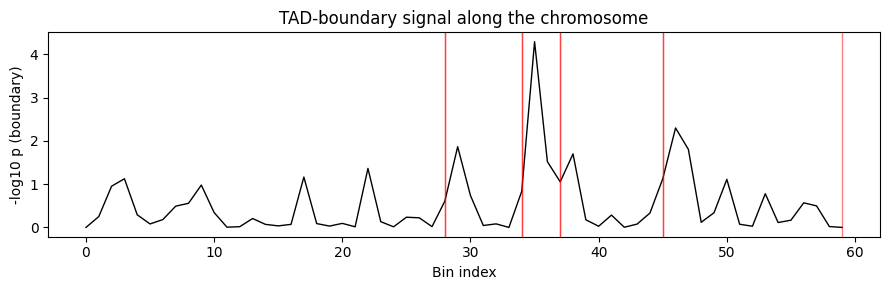

In [6]:
# Recompute the per-bin statistic directly so we can plot it.
from uchrom.fea.arc import axis_variance_cube, filter_normalize, axis_weight
from uchrom.strc.tad.arc_pval import _boundary_pvals

cube = axis_variance_cube(cd, chrom=chrom, device='auto')
cube = filter_normalize(cube)
w = axis_weight(cd, chrom=chrom, device='auto')
pvals_track, _ = _boundary_pvals(
    cube['norm_var'], cube['count'],
    np.array([(s+e)*0.5 for s,e in cube['bin_ids']]),
    w, window_bp=1e5,
)
neg_log_p = -np.log10(np.clip(np.where(np.isfinite(pvals_track), pvals_track, 1.0), 1e-300, 1.0))

fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(np.arange(len(neg_log_p)), neg_log_p, 'k-', lw=1)
ax.set_xlabel('Bin index'); ax.set_ylabel('-log10 p (boundary)')
ax.set_title('TAD-boundary signal along the chromosome')
# Mark level-1 boundary bins
for _, r in top_level.iterrows():
    for bp in (r['start'], r['end']):
        k = bin_of(bp)
        if 0 < k < B:
            ax.axvline(k, color='red', alpha=0.5, lw=1)
plt.tight_layout()
plt.show()


## Notes

- The variance-normalisation preprocessing is shared with
  :func:`uchrom.strc.loop.call_loops_axiswise_f` — you only pay for it
  once per chromosome if you cache.
- For a "flat" TAD partition set ``hierarchical=False`` or just use
  ``level == 1``.
- This caller complements the classical directionality-index method
  available in :func:`uchrom.strc.tad.get_domains`; they agree on
  strong TADs and disagree on boundary-marginal ones.
